# Context Displacement Vector Analysis

Analyses whether context displacement vectors are aligned given a consistent underlying category
Two analyses:
1. **Consistency** — within- vs between-category cosine similarity of context_displacement_vectors. within-category cosine is mean of cosine sim of context_displacement vectors between disjoint support sets generated from the same underlying category. Indicates whether context-induced changes are consistent within-category.
2. **RSA** — inter-category similarity structure of context displacement vectors vs embedding mean difference vectors for concepts. 

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

## 1. Within- vs Between-Category Consistency

Within-category: mean pairwise cosine similarity between displacement
vectors from different support sets for the same category.  
Between-category: mean pairwise cosine similarity of displacement vectors taken from support sets drawn from different categories

If the model accentuates a consistent category-specific direction:
- **within > between** at each (position, layer)

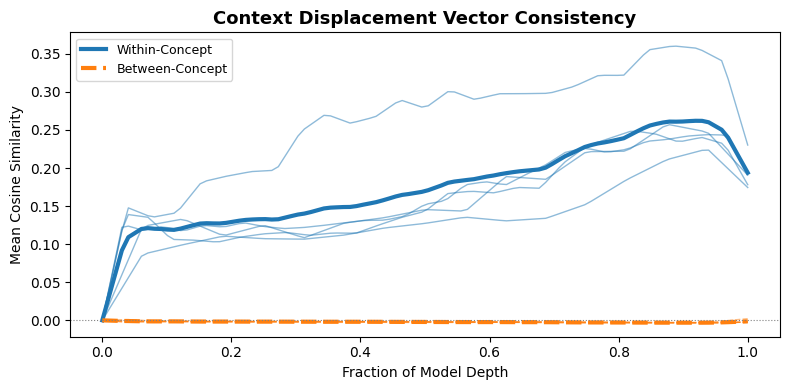

In [2]:
SAVE_DIR = os.path.join("Figures_Final", "summary")
os.makedirs(SAVE_DIR, exist_ok=True)

ALL_MODELS = [
    ("google_gemma-2-2b",      "Gemma-2-2b"),
    ("allenai_OLMo-2-0425-1B", "OLMo-2-1B"),
    ("allenai_OLMo-2-1124-7B", "OLMo-2-7B"),
    ("meta-llama_Llama-3.2-1B","Llama-3.2-1B"),
    ("meta-llama_Llama-3.2-3B","Llama-3.2-3B"),
]
RESULTS_ROOT = "../results_final/categories"

N_INTERP = 100  # common x-axis resolution
x_common = np.linspace(0, 1, N_INTERP)

within_by_model  = {}
between_by_model = {}

for model_safe, model_label in ALL_MODELS:
    results_dir = os.path.join(RESULTS_ROOT, model_safe, "context_displacement_analysis")
    wp = os.path.join(results_dir, "within_consistency.csv")
    bp = os.path.join(results_dir, "between_consistency.csv")
    if not os.path.exists(wp) or not os.path.exists(bp):
        print(f"Missing consistency CSVs for {model_label} — skipping")
        continue
    w = pd.read_csv(wp).groupby("layer")["within_cat_cosine_sim"].mean()
    b = pd.read_csv(bp).groupby("layer")["between_cat_cosine_sim"].mean()
    x = np.linspace(0, 1, len(w))
    within_by_model[model_safe]  = np.interp(x_common, x, w.values)
    between_by_model[model_safe] = np.interp(x_common, x, b.values)

present = [s for s, _ in ALL_MODELS if s in within_by_model]

within_mat  = np.stack([within_by_model[s]  for s in present])
between_mat = np.stack([between_by_model[s] for s in present])

within_avg  = within_mat.mean(axis=0)
between_avg = between_mat.mean(axis=0)

fig, ax = plt.subplots(figsize=(8, 4))

for row in within_mat:
    ax.plot(x_common, row, color="C0", linewidth=1, alpha=0.5)
for row in between_mat:
    ax.plot(x_common, row, color="C1", linewidth=1, alpha=0.5, linestyle="--")

ax.plot(x_common, within_avg,  color="C0", linewidth=3.0, alpha=1.0, label="Within-Concept")
ax.plot(x_common, between_avg, color="C1", linewidth=3.0, alpha=1.0, linestyle="--", label="Between-Concept")

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Fraction of Model Depth")
ax.set_ylabel("Mean Cosine Similarity")
ax.set_title("Context Displacement Vector Consistency", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

fig.savefig(os.path.join(SAVE_DIR, "consistency.pdf"), format="pdf", bbox_inches="tight")

## 2a. Representational Similarity Matrices (RSMs)

Compare the inter-category similarity structure of:
- **Embedding hypothesis RSM**: from static input embeddings (position-free)
- **Context Displacement Vector RSM**: from context displacement vectors at a particular layer

Categories are sorted by hierarchical clustering of the embedding RSM.
A similar block structure in both matrices supports the RSA.

In [3]:
# ── Configuration ────────────────────────────────────────────────────────────
MODEL_NAME  = "google_gemma-2-2b"
RESULTS_DIR = f"../results_final/categories/{MODEL_NAME}/context_displacement_analysis"
MODEL_LABEL = "Gemma-2-2B"
SAVE_DIR = os.path.join("Figures_Final", MODEL_LABEL)

os.makedirs(SAVE_DIR, exist_ok=True)

rsa_by_n_supports = pd.read_csv(os.path.join(RESULTS_DIR, "rsa_by_n_supports.csv"))

# rsa_summary = RSA at max support sets (the full-average result), for backward compatibility
max_k       = rsa_by_n_supports["n_support_sets"].max()
rsa_summary = (
    rsa_by_n_supports[rsa_by_n_supports["n_support_sets"] == max_k]
    .drop(columns=["n_support_sets"])
    .reset_index(drop=True)
)

# Load numpy arrays
mean_cd        = np.load(os.path.join(RESULTS_DIR, "mean_cd.npy"))         # (n_cat, n_layers, d) — mean over support sets
mean_cd_single = np.load(os.path.join(RESULTS_DIR, "mean_cd_single.npy"))  # (n_cat, n_layers, d) — single support set
embed_hyp       = np.load(os.path.join(RESULTS_DIR, "embed_hyp.npy"))        # (n_cat, d)

with open(os.path.join(RESULTS_DIR, "categories.json")) as f:
    categories = json.load(f)

with open(os.path.join(RESULTS_DIR, "hyperparams.json")) as f:
    hparams = json.load(f)

n_layers = mean_cd.shape[1]
n_cat    = len(categories)

print(f"Categories: {n_cat}  |  Layers: {n_layers}")
print(f"mean_cd shape: {mean_cd.shape}")

Categories: 113  |  Layers: 27
mean_cd shape: (113, 27, 2304)


In [4]:
def cluster_order(rsm):
    """Return category indices sorted by hierarchical clustering of the RSM."""
    # Convert similarity to distance
    dist = 1 - rsm
    np.fill_diagonal(dist, 0)
    dist = np.clip(dist, 0, None)
    condensed = squareform(dist, checks=False)
    linkage_mat = linkage(condensed, method="average")
    dend = dendrogram(linkage_mat, no_plot=True)
    return dend["leaves"]


def plot_rsm_pair(embed_rsm, cd_rsm, order, cat_names, layer, model_label):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

    for ax, rsm, title in zip(
        axes,
        [embed_rsm[np.ix_(order, order)], cd_rsm[np.ix_(order, order)]],
        ["Embedding hypothesis RSM", f"cdectory hypothesis RSM (layer={layer})"],
    ):
        im = ax.imshow(rsm, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
        ax.set_title(title, fontsize=11)
        tick_labels = [cat_names[i] for i in order]
        ax.set_xticks(range(len(order)))
        ax.set_yticks(range(len(order)))
        ax.set_xticklabels(tick_labels, rotation=90, fontsize=5)
        ax.set_yticklabels(tick_labels, fontsize=5)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle(f"{model_label}: RSM comparison", fontsize=13, fontweight="bold")
    plt.show()
    return fig

Layer 16 — Spearman ρ (meaned RSM vs embedding):  0.692
Layer 16 — Spearman ρ (single RSM vs embedding):  0.420


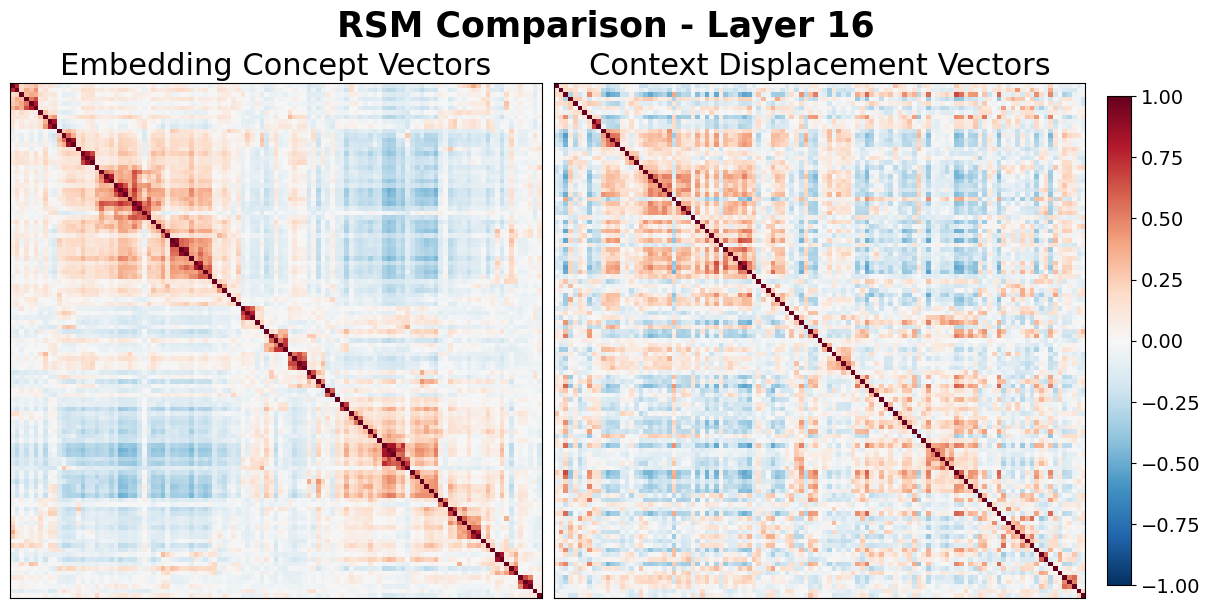

In [5]:
from scipy.stats import spearmanr as _spearmanr

# Build embedding RSM
embed_rsm = embed_hyp @ embed_hyp.T  # (n_cat, n_cat)
order = cluster_order(embed_rsm)

DISPLAY_LAYER = 16

cd_vecs   = mean_cd[:, DISPLAY_LAYER, :]         # (n_cat, d) — mean over support sets
single_vecs = mean_cd_single[:, DISPLAY_LAYER, :]  # (n_cat, d) — single support set

cd_rsm   = cd_vecs   @ cd_vecs.T    # (n_cat, n_cat)
single_rsm = single_vecs @ single_vecs.T  # (n_cat, n_cat)

# Report Spearman ρ: meaned RSM vs embed, and single RSM vs embed
_triu = np.triu_indices(n_cat, k=1)
_embed_flat  = embed_rsm[_triu]
rho_mean,   _ = _spearmanr(_embed_flat, cd_rsm[_triu])
rho_single, _ = _spearmanr(_embed_flat, single_rsm[_triu])
print(f"Layer {DISPLAY_LAYER} — Spearman ρ (meaned RSM vs embedding):  {rho_mean:.3f}")
print(f"Layer {DISPLAY_LAYER} — Spearman ρ (single RSM vs embedding):  {rho_single:.3f}")

rsms = [
    (embed_rsm,  "Embedding Concept Vectors"),
    (single_rsm, f"Context Displacement Vectors"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for i, (ax, (rsm, title)) in enumerate(zip(axes, rsms)):
    im = ax.imshow(rsm[np.ix_(order, order)], vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
    ax.set_title(title, fontsize=22)
    ax.set_xticks([])
    ax.set_yticks([])
    if i == len(rsms) - 1:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=14)

fig.suptitle(f"RSM Comparison - Layer {DISPLAY_LAYER}", fontsize=25, fontweight="bold")
plt.show()

fig.savefig(os.path.join(SAVE_DIR, "rsms.pdf"), format="pdf", bbox_inches="tight")

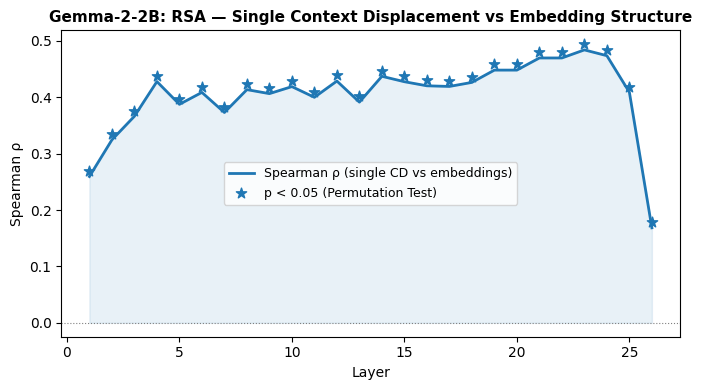

In [8]:
# Plot Spearman Rho over layers for single (non-averaged) context displacement vectors,
# annotated with significance from a permutation test (n_support_sets == 1).
# Layer 0 has no valid rho (embedding layer, no displacement) — filtered out.

rsa_single = (
    rsa_by_n_supports[rsa_by_n_supports["n_support_sets"] == 1]
    .dropna(subset=["spearman_r"])
    .reset_index(drop=True)
)

layers = rsa_single["layer"].values
rho    = rsa_single["spearman_r"].values
pvals  = rsa_single["perm_p_spearman"].values

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(layers, rho, color="C0", linewidth=2, label="Spearman ρ (single CD vs embeddings)")
ax.fill_between(layers, 0, rho, color="C0", alpha=0.1)

sig_mask = pvals < 0.05
ax.scatter(layers[sig_mask], rho[sig_mask] + 0.01, marker="*", color="C0", s=60, zorder=5,
           label="p < 0.05 (Permutation Test)")

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Layer")
ax.set_ylabel("Spearman ρ")
ax.set_title(f"{MODEL_LABEL}: RSA — Single Context Displacement vs Embedding Structure",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "rsa_spearman_by_layer.pdf"), format="pdf", bbox_inches="tight")